# Shot quality on an NBA court

Where does a team take its shots, and does it make more of them than an average team would from the same spots?
This recipe answers both for every field goal attempt of the 2025-26 NBA regular season, with three
SportsDataverse packages working together:

- [sportsdataverse-py](https://py.sportsdataverse.org) loads the shots (the stats-API shot file the
  SportsDataverse publishes on GitHub, so nothing calls stats.nba.com),
- [sdvplot](https://sdvplot.sportsdataverse.org) moves them onto sportypy's court and supplies team colors and
  logos,
- sportypy draws the court and bins the shots onto it with `hexbin`.

To run it yourself: `pip install sportypy sportsdataverse "sdvplot[surfaces]"`, or from a clone of the repository, `uv run --group cookbook jupyter lab`.

In [1]:
import matplotlib.pyplot as plt
import polars as pl
import sportsdataverse.nba as nba
from matplotlib.colors import TwoSlopeNorm

import sdvplot
from sportypy.surfaces.basketball import NBACourt

# print tables as markdown, so the docs site shows them as tables
pl.Config.set_tbl_formatting("ASCII_MARKDOWN")
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)
SEASON = 2025  # this loader names a season by the year it starts: 2025 is 2025-26

## 1. Every shot, on sportypy's frame

The stats API reports a shot's location in tenths of a foot with the hoop at the origin. sportypy's court is in
feet with the origin at center court. `sdvplot.court_coords` converts one to the other and adds `court_x` and
`court_y`; every shot lands on the left half of the court. A shot's value is `points` when it goes in and 0 when it
does not.

In [2]:
shots = sdvplot.court_coords(
    nba.load_nba_stats_shots(seasons=SEASON).filter(pl.col("season_type_id") == "2")  # 2: regular season
).with_columns(
    made=pl.col("shot_result") == "Made",
    points=pl.when(pl.col("shot_result") == "Made").then(pl.col("shot_value")).otherwise(0),
)
print(f"{shots.height:,} shots by {shots['team_tricode'].n_unique()} teams")
print(shots.select("team_tricode", "player_name", "shot_value", "shot_distance", "court_x", "court_y", "points").head(3))

219,159 shots by 30 teams
| team_tricode | player_name | shot_value | shot_distance | court_x | court_y | points |
|--------------|-------------|------------|---------------|---------|---------|--------|
| HOU          | Sengun      | 3          | 25            | -23.85  | -17.9   | 0      |
| OKC          | Holmgren    | 2          | 1             | -40.45  | 0.0     | 2      |
| HOU          | Thompson    | 3          | 23            | -41.75  | 23.3    | 0      |


## 2. Where the league shoots

`NBACourt.hexbin` bins the points into hexagons sized in feet (`binsize`) and clips them to the court.
`display_range="defense"` draws only the left half, where every shot is. The log color scale keeps the rim, which
has many times more attempts than anywhere else, from washing out the rest: the rim, the corners and the arc are
the darkest, and the long two in between takes about a tenth as many shots as the arc.

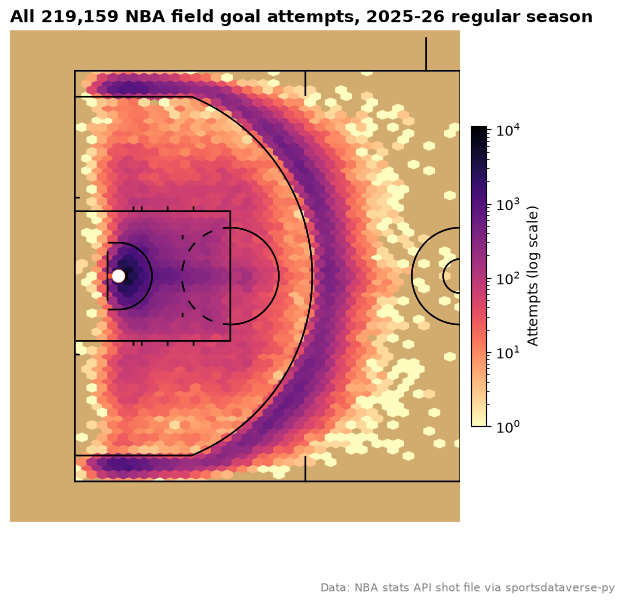

In [3]:
court = NBACourt()
fig, ax = plt.subplots(figsize=(7, 6.5))
court.draw(ax=ax, display_range="defense")
hexes = court.hexbin(shots["court_x"], shots["court_y"], binsize=1.5, bins="log", cmap="magma_r", mincnt=1, ax=ax)
fig.colorbar(hexes, ax=ax, shrink=0.6, pad=0.02, label="Attempts (log scale)")
ax.set_title(f"All {shots.height:,} NBA field goal attempts, 2025-26 regular season", loc="left", fontweight="bold")
fig.text(0.99, 0.01, "Data: NBA stats API shot file via sportsdataverse-py", ha="right", fontsize=8, color="grey")
plt.show()

## 3. What a shot is worth from each distance

The league's average points per attempt at each distance (in whole feet, with everything past 35 feet pooled) and
shot value is the baseline for the rest of the recipe: an average team's expected return on the same shot. A two
at the rim is worth well over a point; the long two is the worst shot on the floor, and a step back behind the
arc is worth more than a step in.

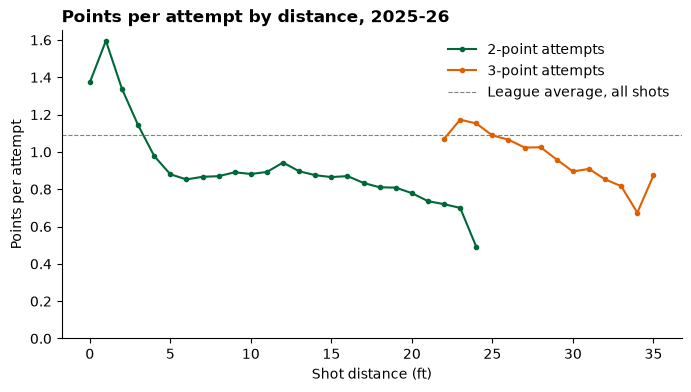

In [4]:
expected = (
    shots.with_columns(dist=pl.col("shot_distance").clip(upper_bound=35))
    .group_by("dist", "shot_value")
    .agg(attempts=pl.len(), xpts=pl.col("points").mean())
    .filter(pl.col("attempts") >= 50)
    .sort("dist")
)

fig, ax = plt.subplots(figsize=(8, 4))
for value, color in ((2, "#006838"), (3, "#e06000")):
    line = expected.filter(pl.col("shot_value") == value)
    ax.plot(line["dist"], line["xpts"], marker="o", ms=3, color=color, label=f"{value}-point attempts")
ax.axhline(shots["points"].mean(), color="grey", lw=0.8, ls="--", label="League average, all shots")
ax.set(xlabel="Shot distance (ft)", ylabel="Points per attempt", ylim=(0, None))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Points per attempt by distance, 2025-26", loc="left", fontweight="bold")
plt.show()

## 4. Points over expected, shot by shot

Join the baseline back onto every shot and each one gets an expected value, `xpts`. A make from a spot where the
league scores 1.1 points per attempt is worth 2 - 1.1 = +0.9 over expected, a miss there -1.1. Summed over a
season, that separates teams that take good shots (a high `xpts` per attempt) from teams that make the shots they
take (a high `over` per attempt).

In [5]:
shots = shots.with_columns(dist=pl.col("shot_distance").clip(upper_bound=35)).join(
    expected.select("dist", "shot_value", "xpts"), on=["dist", "shot_value"], how="left"
).with_columns(over=pl.col("points") - pl.col("xpts"))

teams = (
    shots.drop_nulls("xpts")
    .group_by("team_tricode")
    .agg(attempts=pl.len(), pts=pl.col("points").mean(), xpts=pl.col("xpts").mean(), over=pl.col("over").mean())
    .sort("over", descending=True)
)
with pl.Config(float_precision=3, tbl_rows=10):
    print(pl.concat([teams.head(5), teams.tail(5)]))

| team_tricode | attempts | pts   | xpts  | over   |
|--------------|----------|-------|-------|--------|
| LAL          | 6863     | 1.146 | 1.069 | 0.077  |
| DEN          | 7196     | 1.154 | 1.079 | 0.075  |
| BOS          | 7398     | 1.106 | 1.052 | 0.053  |
| LAC          | 6857     | 1.118 | 1.072 | 0.045  |
| MIL          | 7012     | 1.131 | 1.093 | 0.037  |
| PHI          | 7404     | 1.061 | 1.098 | -0.037 |
| CHI          | 7417     | 1.095 | 1.146 | -0.051 |
| POR          | 7389     | 1.067 | 1.119 | -0.051 |
| BKN          | 6933     | 1.041 | 1.106 | -0.065 |
| NOP          | 7420     | 1.054 | 1.122 | -0.068 |


## 5. Where the best and worst shooting teams beat the league

Pass `over` as the hexbin's `values` and each hexagon shows the team's average points over expected there
(`mincnt` leaves out spots with too few attempts to say). A diverging palette centered on zero puts the league
average in white. The courts are painted in each team's colors from sdvplot (`team_colors`), handed to sportypy as
`color_updates`, and `add_logos` puts the team's logo beyond the arc.

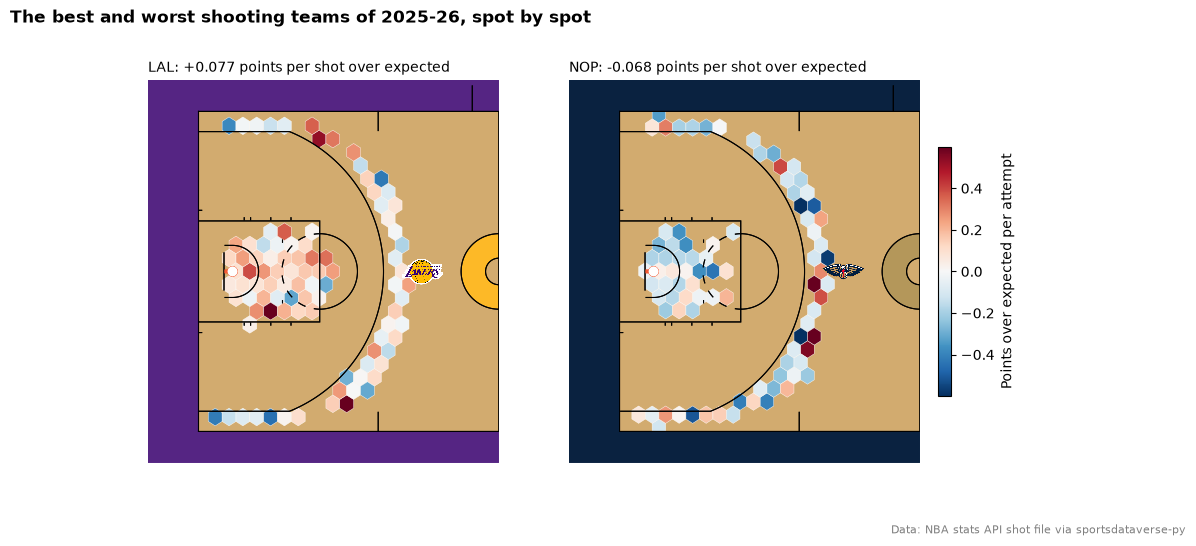

In [6]:
best, worst = teams["team_tricode"][0], teams["team_tricode"][-1]
norm = TwoSlopeNorm(vcenter=0, vmin=-0.6, vmax=0.6)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, team in zip(axes, (best, worst)):
    primary = sdvplot.team_colors("nba", team)
    secondary = sdvplot.team_colors("nba", team, which="secondary")
    court = NBACourt(color_updates={"court_apron": primary, "center_circle_fill": secondary})
    court.draw(ax=ax, display_range="defense")
    mine = shots.filter((pl.col("team_tricode") == team) & pl.col("over").is_not_null())
    hexes = court.hexbin(mine["court_x"], mine["court_y"], values=mine["over"], binsize=4, mincnt=20,
                         cmap="RdBu_r", norm=norm, edgecolors="white", linewidths=0.3, ax=ax)
    sdvplot.add_logos(ax, [-12], [0], [team], league="nba", height=0.12, zorder=30)
    row = teams.filter(pl.col("team_tricode") == team).row(0, named=True)
    ax.set_title(f"{team}: {row['over']:+.3f} points per shot over expected", loc="left", fontsize=10)
fig.colorbar(hexes, ax=axes, shrink=0.6, pad=0.02, label="Points over expected per attempt")
fig.suptitle("The best and worst shooting teams of 2025-26, spot by spot", x=0.01, ha="left", fontweight="bold")
fig.text(0.99, 0.01, "Data: NBA stats API shot file via sportsdataverse-py", ha="right", fontsize=8, color="grey")
plt.show()

## Where to go next

- The [`NBACourt` reference](https://sportypy.sportsdataverse.org/docs/reference/surfaces/basketball) lists every feature `color_updates` can repaint, and
  the [plotting reference](https://sportypy.sportsdataverse.org/docs/reference/plotting) every option of `hexbin`, `heatmap` and `contour`.
- sdvplot's [surfaces and shot charts cookbook](https://sdvplot.sportsdataverse.org/docs/cookbooks/surfaces-and-shot-charts)
  draws single-player shot charts on team-colored courts in one call.
- Swap `nba` for `wnba` (`load_wnba_stats_shots`, `sdvplot.court_coords` and `sportypy`'s `WNBACourt`) and the
  recipe runs unchanged on the WNBA.